In [1]:
# ============================================================
# BLOCK A — build survival dataset from a stratified sample
# 300k loans, sampled per chunk so the full 2.26M frame never
# exists in memory. issue_d KEPT — needed for exit_type in Block E.
# ============================================================
import os, gc
os.environ['TMP'] = os.environ['TEMP'] = r'X:\Projects\credit-pd-engine\tmp'
os.makedirs(os.environ['TMP'], exist_ok=True)

import pandas as pd, numpy as np
from lifelines import KaplanMeierFitter, CoxPHFitter, AalenJohansenFitter
from lifelines.utils import concordance_index

SURV_CACHE  = 'data/processed/survival_sample.parquet'
SNAPSHOT    = pd.Timestamp('2018-12-31')
SAMPLE_FRAC = 0.14                      # ~300k of 2.26M
BAD = ['Charged Off', 'Default',
       'Does not meet the credit policy. Status:Charged Off']

if os.path.exists(SURV_CACHE):
    surv = pd.read_parquet(SURV_CACHE)
    print("Loaded from cache.")
else:
    cols = ['issue_d','loan_status','last_pymnt_d','term','loan_amnt',
            'annual_inc','dti','fico_range_low','inq_last_6mths',
            'purpose','home_ownership','verification_status']
    dtypes = {c: 'float32' for c in
              ['loan_amnt','annual_inc','dti','fico_range_low','inq_last_6mths']}

    parts, n_raw = [], 0
    for ch in pd.read_csv('data/accepted_2007_to_2018Q4.csv.gz', compression='gzip',
                          usecols=cols, dtype=dtypes, chunksize=100_000):
        # Sample FIRST — everything below runs on 14% of the rows
        ch = ch.sample(frac=SAMPLE_FRAC, random_state=42)
        n_raw += len(ch)

        # Malformed dates/terms -> NaT/NaN, then dropped
        ch['issue_d'] = pd.to_datetime(ch['issue_d'], format='%b-%Y',
                                       errors='coerce')
        ch['term_m']  = ch['term'].str.extract(r'(\d+)').astype('float32')
        ch = ch[ch['issue_d'].notna() & ch['term_m'].notna()]
        if len(ch) == 0:
            continue

        lp = pd.to_datetime(ch['last_pymnt_d'], format='%b-%Y', errors='coerce')

        ch['vintage'] = ch['issue_d'].dt.year.astype('int16')
        ch['event']   = ch['loan_status'].isin(BAD).astype('int8')

        # No recorded last payment -> treat as still running to snapshot
        end = lp.fillna(SNAPSHOT).clip(upper=SNAPSHOT)
        ch['duration'] = ((end.dt.year - ch['issue_d'].dt.year) * 12
                          + (end.dt.month - ch['issue_d'].dt.month)).astype('float32')

        ch = ch[(ch['duration'] > 0) & (ch['duration'] <= ch['term_m'])
                & ch['fico_range_low'].notna() & ch['annual_inc'].notna()]

        for c in ['purpose','home_ownership','verification_status']:
            ch[c] = ch[c].astype('category')

        # issue_d retained: exit_type needs the true origination month,
        # not a mid-year proxy. Costs ~2 MB.
        parts.append(ch.drop(columns=['loan_status','last_pymnt_d','term']))
        del ch

    surv = pd.concat(parts, ignore_index=True)
    del parts; gc.collect()
    surv.to_parquet(SURV_CACHE, index=False)
    print(f"Built and cached. Sampled {n_raw:,} rows -> kept {len(surv):,}")

print(f"\n{len(surv):,} loans | event rate {surv['event'].mean():.3f}")
print(f"Median duration: {surv['duration'].median():.0f} months")
print(f"Memory: {surv.memory_usage(deep=True).sum()/1e6:.0f} MB\n")
print(surv.groupby('vintage').agg(n=('event','size'),
                                  event_rate=('event','mean')).round(3).to_string())

Built and cached. Sampled 316,498 rows -> kept 302,514

302,514 loans | event rate 0.123
Median duration: 16 months
Memory: 48 MB

             n  event_rate
vintage                   
2007        77       0.416
2008       282       0.241
2009       608       0.179
2010      1461       0.149
2011      2533       0.170
2012      6930       0.172
2013     17883       0.162
2014     31298       0.181
2015     55934       0.187
2016     60461       0.156
2017     61785       0.089
2018     63262       0.019


In [2]:
import os
p = 'data/processed/survival_sample.parquet'
if os.path.exists(p): os.remove(p); print("removed")

removed


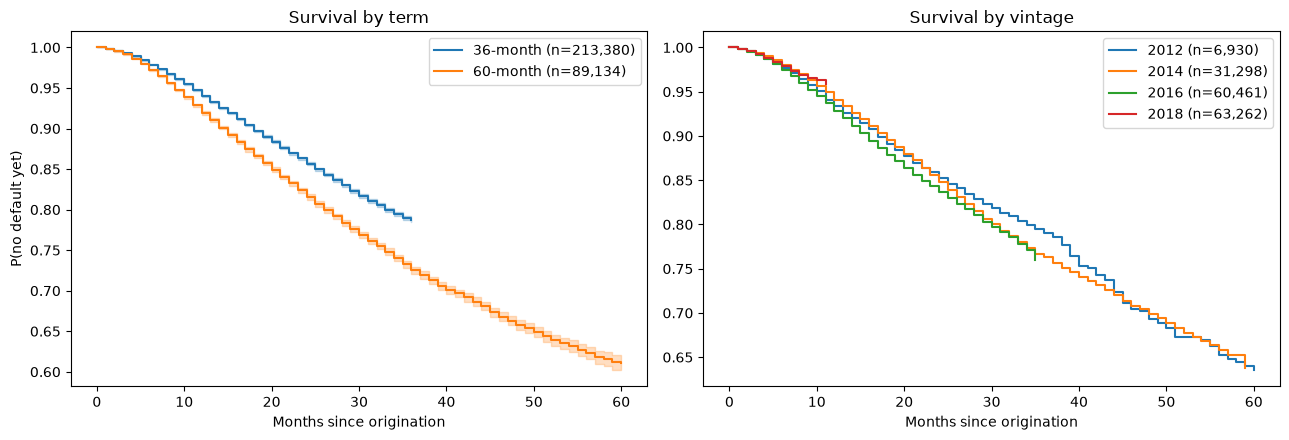

 month   S(t)  cum_default_%  marginal_%
     6 0.9770           2.30        2.30
    12 0.9341           6.59        4.29
    18 0.8877          11.23        4.64
    24 0.8439          15.61        4.38
    30 0.8017          19.83        4.22
    36 0.7659          23.41        3.58
    48 0.6947          30.53        7.12
    60 0.6450          35.50        4.97


C:\Users\Rashtra Mitra\AppData\Local\Temp\ipykernel_15212\1531782253.py:27: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  'S(t)': [round(float(sf.loc[:m].iloc[-1]), 4) for m in pts]})


In [3]:
# ============================================================
# BLOCK B — Kaplan-Meier: when do defaults happen?
# ============================================================
import matplotlib.pyplot as plt
kmf = KaplanMeierFitter()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for t in [36, 60]:
    s = surv[surv['term_m'] == t]
    kmf.fit(s['duration'], s['event'], label=f'{t}-month (n={len(s):,})')
    kmf.plot_survival_function(ax=ax[0], ci_show=True)
ax[0].set(xlabel='Months since origination', ylabel='P(no default yet)',
          title='Survival by term')

for v in [2012, 2014, 2016, 2018]:
    s = surv[surv['vintage'] == v]
    if len(s) > 2000:
        kmf.fit(s['duration'], s['event'], label=f'{v} (n={len(s):,})')
        kmf.plot_survival_function(ax=ax[1], ci_show=False)
ax[1].set(xlabel='Months since origination', title='Survival by vintage')
plt.tight_layout(); plt.show()

kmf.fit(surv['duration'], surv['event'])
sf = kmf.survival_function_
pts = [6, 12, 18, 24, 30, 36, 48, 60]
h = pd.DataFrame({'month': pts,
                  'S(t)': [round(float(sf.loc[:m].iloc[-1]), 4) for m in pts]})
h['cum_default_%'] = ((1 - h['S(t)']) * 100).round(2)
h['marginal_%']    = h['cum_default_%'].diff().fillna(h['cum_default_%']).round(2)
print(h.to_string(index=False))

In [4]:
# ============================================================
# BLOCK C — does KM close the Phase 5 calibration gap?
# Classifier: 2015 bad rate 0.2019 (unresolved loans DROPPED)
# Scorecard predicted 0.1720. PSI 0.0005 ruled out population drift.
# KM uses every loan including censored ones — what does it say?
# ============================================================
rows = []
for v in [2013, 2014, 2015, 2016]:
    s = surv[surv['vintage'] == v]
    if len(s) < 2000:
        continue
    kmf.fit(s['duration'], s['event'])
    horizon = min(60, int(s['duration'].max()))
    resolved = s[s['duration'] < s['term_m']]           # crude proxy
    rows.append({
        'vintage': v, 'n': len(s),
        'naive_event_%': round(s['event'].mean()*100, 2),
        'KM_lifetime_%': round((1 - float(kmf.survival_function_
                                .loc[:horizon].iloc[-1]))*100, 2),
        'max_obs_month': int(s['duration'].max()),
    })

print(pd.DataFrame(rows).to_string(index=False))
print(f"\nClassifier 2015 test bad rate : 20.19%")
print(f"Scorecard mean predicted PD   : 17.20%")

C:\Users\Rashtra Mitra\AppData\Local\Temp\ipykernel_15212\3286532307.py:18: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  'KM_lifetime_%': round((1 - float(kmf.survival_function_
C:\Users\Rashtra Mitra\AppData\Local\Temp\ipykernel_15212\3286532307.py:18: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  'KM_lifetime_%': round((1 - float(kmf.survival_function_
C:\Users\Rashtra Mitra\AppData\Local\Temp\ipykernel_15212\3286532307.py:18: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  'KM_lifetime_%': round((1 - float(kmf.survival_function_
C:\Users\Rashtra Mitra\AppData\Local\Temp\ipykernel_15212\3286532307.py:18: FutureWarning: Calling float on a single element Series is deprecated and will raise a Typ

 vintage     n  naive_event_%  KM_lifetime_%  max_obs_month
    2013 17883          16.22          34.27             60
    2014 31298          18.10          36.24             59
    2015 55934          18.66          31.02             47
    2016 60461          15.61          23.97             35

Classifier 2015 test bad rate : 20.19%
Scorecard mean predicted PD   : 17.20%


In [5]:
# ============================================================
# BLOCK D — Cox proportional hazards
# Origination-time features only. Trained 2007-2014, tested on 2015 —
# same split as every other notebook.
# ============================================================
tr = surv[surv['vintage'].between(2007, 2014)]
te = surv[surv['vintage'] == 2015]

def prep(d, ref):
    out = pd.DataFrame(index=d.index)
    out['duration']       = d['duration']
    out['event']          = d['event']
    out['fico']           = (d['fico_range_low'] - 700) / 10
    out['dti']            = d['dti']
    out['log_inc']        = np.log1p(d['annual_inc'])
    out['loan_amnt_k']    = d['loan_amnt'] / 1000
    out['inq_6m']         = d['inq_last_6mths']
    out['term_60']        = (d['term_m'] == 60).astype(int)
    for c in ['purpose','home_ownership','verification_status']:
        for lvl in ref[c].value_counts().index[1:5]:
            out[f'{c[:4]}_{lvl}'] = (d[c] == lvl).astype(int)
    return out.dropna()

Xtr, Xte = prep(tr, tr), prep(te, tr)
cph = CoxPHFitter(penalizer=0.1).fit(Xtr, 'duration', 'event')
print(cph.summary[['coef','exp(coef)','p']].round(4).to_string())

c_tr = concordance_index(Xtr['duration'], -cph.predict_partial_hazard(Xtr), Xtr['event'])
c_te = concordance_index(Xte['duration'], -cph.predict_partial_hazard(Xte), Xte['event'])
print(f"\nC-index  train {c_tr:.4f} | test {c_te:.4f}")
print(f"Scorecard AUC 0.7076 | XGBoost AUC 0.7165")

x:\Projects\credit-pd-engine\venv\Lib\site-packages\lifelines\utils\__init__.py:1100: ConvergenceWarning: Column(s) ['home_NONE'] have very low variance. This may harm convergence. 1) Are you using formula's? Did you mean to add '-1' to the end. 2) Try dropping this redundant column before fitting if convergence fails.

  warnings.warn(dedent(warning_text), ConvergenceWarning)


                         coef  exp(coef)       p
covariate                                       
fico                  -0.0567     0.9449  0.0000
dti                    0.0089     1.0089  0.0000
log_inc               -0.2345     0.7909  0.0000
loan_amnt_k            0.0050     1.0050  0.0000
inq_6m                 0.1054     1.1111  0.0000
term_60                0.1770     1.1937  0.0000
purp_credit_card      -0.1656     0.8474  0.0000
purp_home_improvement -0.0372     0.9635  0.2930
purp_other             0.1018     1.1071  0.0041
purp_major_purchase   -0.0555     0.9460  0.3296
home_RENT              0.1515     1.1636  0.0000
home_OWN               0.0340     1.0346  0.2232
home_OTHER             0.7356     2.0867  0.0225
home_NONE              0.9830     2.6725  0.3249
veri_Source Verified   0.0127     1.0128  0.4542
veri_Not Verified     -0.0966     0.9079  0.0000

C-index  train 0.6385 | test 0.6363
Scorecard AUC 0.7076 | XGBoost AUC 0.7165


In [6]:
# ============================================================
# BLOCK E — competing risks: default vs prepayment
# KM overestimates because it treats prepayment as censoring.
# Aalen-Johansen estimates each exit type without assuming the
# other would eventually default.
# ============================================================
from lifelines import AalenJohansenFitter

# 3-state outcome: 0 = still running (true censoring)
#                  1 = default
#                  2 = prepaid / fully paid  <- competing event, NOT censoring
surv['exit_type'] = 0
surv.loc[surv['event'] == 1, 'exit_type'] = 1
surv.loc[(surv['event'] == 0) &
         (surv['duration'] < surv['term_m'] - 1), 'exit_type'] = 2

print(surv['exit_type'].value_counts(normalize=True).round(3).to_string(), "\n")

rows = []
for v in [2013, 2014, 2015, 2016]:
    s = surv[surv['vintage'] == v]
    if len(s) < 2000:
        continue
    ajf = AalenJohansenFitter(calculate_variance=False)
    ajf.fit(s['duration'], s['exit_type'], event_of_interest=1)
    cif = ajf.cumulative_density_
    rows.append({
        'vintage': v, 'n': len(s),
        'naive_%':  round(s['event'].mean()*100, 2),
        'AJ_cif_%': round(float(cif.iloc[-1, 0])*100, 2),
        'KM_%':     {2013:34.27, 2014:36.24, 2015:31.02, 2016:23.97}[v],
    })

out = pd.DataFrame(rows)
print(out.to_string(index=False))
print("\n2013 is 100% resolved — its naive rate IS the truth.")
print("Whichever estimator reproduces 16.22% there is the correct one.")

exit_type
2    0.797
1    0.123
0    0.080 

 vintage     n  naive_%  AJ_cif_%  KM_%
    2013 17883    16.22     19.08 34.27
    2014 31298    18.10     19.77 36.24
    2015 55934    18.66     19.36 31.02
    2016 60461    15.61     15.61 23.97

2013 is 100% resolved — its naive rate IS the truth.
Whichever estimator reproduces 16.22% there is the correct one.


In [7]:
# ============================================================
# BLOCK E2 — fix exit_type: current loans are censored, not prepaid
# last_pymnt_d for a CURRENT loan is just its most recent payment,
# so distance-from-term can't identify prepayment. Distance from
# the snapshot can: still paying near 2018-12 => still running.
# ============================================================
# Rebuild duration-to-snapshot per loan
snap_m = (SNAPSHOT.year * 12 + SNAPSHOT.month)
surv['months_to_snap'] = snap_m - (surv['vintage'] * 12 + 6) - surv['duration']

surv['exit_type'] = 0
surv.loc[surv['event'] == 1, 'exit_type'] = 1
# Prepaid/settled: stopped paying well before snapshot AND before term end
surv.loc[(surv['event'] == 0)
         & (surv['months_to_snap'] > 4)
         & (surv['duration'] < surv['term_m'] - 1), 'exit_type'] = 2

print(surv['exit_type'].value_counts(normalize=True).round(3).to_string())
print("\nexit_type by vintage (share):")
print(pd.crosstab(surv['vintage'], surv['exit_type'],
                  normalize='index').round(3).to_string())

exit_type
0    0.488
2    0.389
1    0.123

exit_type by vintage (share):
exit_type      0      1      2
vintage                       
2007       0.377  0.416  0.208
2008       0.305  0.241  0.454
2009       0.281  0.179  0.539
2010       0.229  0.149  0.623
2011       0.226  0.170  0.604
2012       0.296  0.172  0.532
2013       0.259  0.162  0.579
2014       0.244  0.181  0.575
2015       0.282  0.187  0.532
2016       0.405  0.156  0.439
2017       0.587  0.089  0.323
2018       0.878  0.019  0.102


In [8]:
rows = []
for v in [2013, 2014, 2015, 2016]:
    s = surv[surv['vintage'] == v]
    ajf = AalenJohansenFitter(calculate_variance=False)
    ajf.fit(s['duration'], s['exit_type'], event_of_interest=1)
    rows.append({'vintage': v, 'n': len(s),
                 'naive_%':  round(s['event'].mean()*100, 2),
                 'AJ_v2_%':  round(float(ajf.cumulative_density_.iloc[-1, 0])*100, 2),
                 'AJ_v1_%':  {2013:19.08, 2014:19.77, 2015:19.36, 2016:15.61}[v],
                 'KM_%':     {2013:34.27, 2014:36.24, 2015:31.02, 2016:23.97}[v]})
print(pd.DataFrame(rows).to_string(index=False))

 vintage     n  naive_%  AJ_v2_%  AJ_v1_%  KM_%
    2013 17883    16.22    19.08    19.08 34.27
    2014 31298    18.10    20.54    19.77 36.24
    2015 55934    18.66    20.41    19.36 31.02
    2016 60461    15.61    17.38    15.61 23.97


In [9]:
# ============================================================
# BLOCK E3 — exit_type from true origination month
# ============================================================
snap_m = SNAPSHOT.year * 12 + SNAPSHOT.month
issue_m = surv['issue_d'].dt.year * 12 + surv['issue_d'].dt.month
surv['months_to_snap'] = snap_m - issue_m - surv['duration']

surv['exit_type'] = 0
surv.loc[surv['event'] == 1, 'exit_type'] = 1
surv.loc[(surv['event'] == 0)
         & (surv['months_to_snap'] > 3)
         & (surv['duration'] < surv['term_m'] - 1), 'exit_type'] = 2

print(pd.crosstab(surv['vintage'], surv['exit_type'],
                  normalize='index').round(3).to_string())

exit_type      0      1      2
vintage                       
2007       0.377  0.416  0.208
2008       0.305  0.241  0.454
2009       0.281  0.179  0.539
2010       0.229  0.149  0.623
2011       0.226  0.170  0.604
2012       0.296  0.172  0.532
2013       0.260  0.162  0.578
2014       0.260  0.181  0.559
2015       0.312  0.187  0.502
2016       0.471  0.156  0.373
2017       0.719  0.089  0.192
2018       0.955  0.019  0.026


In [10]:
# ============================================================
# BLOCK E4 — exit_type: ANY repayment is a competing event
# A loan that reached maturity exited just as definitively as
# one that prepaid. Only loans still paying at snapshot are censored.
# ============================================================
snap_m  = SNAPSHOT.year * 12 + SNAPSHOT.month
issue_m = surv['issue_d'].dt.year * 12 + surv['issue_d'].dt.month
surv['months_to_snap'] = snap_m - issue_m - surv['duration']

surv['exit_type'] = 0
surv.loc[surv['event'] == 1, 'exit_type'] = 1
# Repaid = not defaulted AND stopped paying >3 months before snapshot.
# No term condition — full-term completions count too.
surv.loc[(surv['event'] == 0) & (surv['months_to_snap'] > 3), 'exit_type'] = 2

print(pd.crosstab(surv['vintage'], surv['exit_type'],
                  normalize='index').round(3).to_string())

exit_type      0      1      2
vintage                       
2007       0.000  0.416  0.584
2008       0.000  0.241  0.759
2009       0.000  0.179  0.821
2010       0.000  0.149  0.851
2011       0.000  0.170  0.830
2012       0.000  0.172  0.828
2013       0.016  0.162  0.822
2014       0.083  0.181  0.736
2015       0.207  0.187  0.607
2016       0.471  0.156  0.373
2017       0.719  0.089  0.192
2018       0.955  0.019  0.026


In [11]:
rows = []
for v in [2013, 2014, 2015, 2016]:
    s = surv[surv['vintage'] == v]
    ajf = AalenJohansenFitter(calculate_variance=False)
    ajf.fit(s['duration'], s['exit_type'], event_of_interest=1)
    rows.append({'vintage': v, 'n': len(s),
                 'naive_%': round(s['event'].mean()*100, 2),
                 'AJ_v3_%': round(float(ajf.cumulative_density_.iloc[-1, 0])*100, 2),
                 'KM_%':    {2013:34.27, 2014:36.24, 2015:31.02, 2016:23.97}[v]})
print(pd.DataFrame(rows).to_string(index=False))
print("\n2013 truth = 16.22%")

 vintage     n  naive_%  AJ_v3_%  KM_%
    2013 17883    16.22    16.22 34.27
    2014 31298    18.10    18.56 36.24
    2015 55934    18.66    19.87 31.02
    2016 60461    15.61    17.94 23.97

2013 truth = 16.22%


In [12]:
# ============================================================
# BLOCK F — persist the lifetime PD table for figures/make_figures.py
# ============================================================
from lifelines import KaplanMeierFitter, AalenJohansenFitter

rows = []
for v in [2013, 2014, 2015, 2016]:
    s = surv[surv['vintage'] == v]

    kmf_ = KaplanMeierFitter()
    kmf_.fit(s['duration'], s['event'])
    horizon = min(60, int(s['duration'].max()))
    km = (1 - float(kmf_.survival_function_.loc[:horizon].iloc[-1])) * 100

    ajf_ = AalenJohansenFitter(calculate_variance=False)
    ajf_.fit(s['duration'], s['exit_type'], event_of_interest=1)
    aj = float(ajf_.cumulative_density_.iloc[-1, 0]) * 100

    rows.append({'vintage': v,
                 'resolved_only': round(s['event'].mean() * 100, 2),
                 'aalen_johansen': round(aj, 2),
                 'kaplan_meier': round(km, 2)})

lifetime_pd = pd.DataFrame(rows).set_index('vintage')
lifetime_pd.to_csv('data/processed/lifetime_pd.csv')
print(lifetime_pd.to_string())
print("\nSaved -> data/processed/lifetime_pd.csv")

C:\Users\Rashtra Mitra\AppData\Local\Temp\ipykernel_15212\3152235048.py:13: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  km = (1 - float(kmf_.survival_function_.loc[:horizon].iloc[-1])) * 100
C:\Users\Rashtra Mitra\AppData\Local\Temp\ipykernel_15212\3152235048.py:13: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  km = (1 - float(kmf_.survival_function_.loc[:horizon].iloc[-1])) * 100
C:\Users\Rashtra Mitra\AppData\Local\Temp\ipykernel_15212\3152235048.py:13: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  km = (1 - float(kmf_.survival_function_.loc[:horizon].iloc[-1])) * 100


         resolved_only  aalen_johansen  kaplan_meier
vintage                                             
2013             16.22           16.22         34.27
2014             18.10           18.56         36.24
2015             18.66           19.87         31.02
2016             15.61           17.94         23.97

Saved -> data/processed/lifetime_pd.csv


C:\Users\Rashtra Mitra\AppData\Local\Temp\ipykernel_15212\3152235048.py:13: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  km = (1 - float(kmf_.survival_function_.loc[:horizon].iloc[-1])) * 100
